Первые строки таблицы:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Размер таблицы (строки, столбцы): (918, 12)

Пропуски по столбцам:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS       

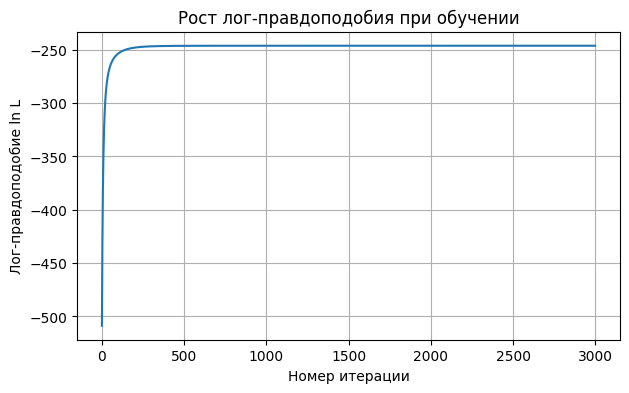

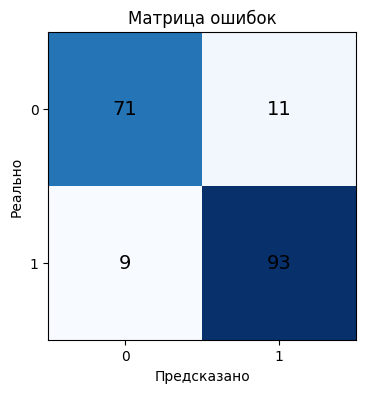

In [1]:
# ПР-4: бинарная классификация методом логистической регрессии
# Датасет: heart.csv (Kaggle, Heart Failure Prediction)
# Положите этот файл рядом с heart.csv и запустите.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score)

# ---------------------------------------------------------------
# 1. Загрузка и первый взгляд на данные
# ---------------------------------------------------------------
df = pd.read_csv("heart.csv")

print("Первые строки таблицы:")
print(df.head())
print("\nРазмер таблицы (строки, столбцы):", df.shape)
print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nСколько здоровых (0) и больных (1):")
print(df["HeartDisease"].value_counts())

# ---------------------------------------------------------------
# 2. Очистка данных
# В Cholesterol и RestingBP нули - это ошибки (так не бывает),
# заменяем их на медиану остальных значений.
# ---------------------------------------------------------------
for col in ["Cholesterol", "RestingBP"]:
    print(f"\nНулей в {col}:", (df[col] == 0).sum())
    median = df.loc[df[col] != 0, col].median()   # медиана без нулей
    df[col] = df[col].replace(0, median)

# ---------------------------------------------------------------
# 3. Кодирование данных
# Текстовые столбцы превращаем в числа (one-hot кодирование)
# ---------------------------------------------------------------
y = df["HeartDisease"]                  # то, что предсказываем
X = df.drop("HeartDisease", axis=1)     # признаки

text_columns = ["Sex", "ChestPainType", "RestingECG",
                "ExerciseAngina", "ST_Slope"]
X = pd.get_dummies(X, columns=text_columns, drop_first=True)
X = X.astype(float)   # все значения делаем числами

print("\nПризнаки после кодирования:")
print(list(X.columns))

# ---------------------------------------------------------------
# 4. Разделение на обучающую и тестовую выборки (80% / 20%)
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("\nРазмер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

# ---------------------------------------------------------------
# 5. Масштабирование признаков
# Масштаб считаем по обучающей выборке и применяем к обеим
# ---------------------------------------------------------------
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# ---------------------------------------------------------------
# 6. Модель из библиотеки sklearn
# ---------------------------------------------------------------
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_sc, y_train)

y_pred = model.predict(X_test_sc)               # классы 0 или 1
y_proba = model.predict_proba(X_test_sc)[:, 1]  # вероятности класса 1

print("\nПервые 5 вероятностей болезни:", y_proba[:5].round(3))
print("Первые 5 предсказаний:        ", y_pred[:5])
print("Первые 5 реальных ответов:    ", y_test.values[:5])

# ---------------------------------------------------------------
# 7. Метрики для модели sklearn
# ---------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
print("\nМатрица ошибок:")
print(cm)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")

print("\nМетрики sklearn:")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1       :", round(f1_score(y_test, y_pred), 3))

# Те же метрики вручную по формулам (должны совпасть)
precision_hand = TP / (TP + FP)
recall_hand = TP / (TP + FN)
f1_hand = 2 * precision_hand * recall_hand / (precision_hand + recall_hand)

print("\nМетрики, посчитанные вручную:")
print("Precision:", round(precision_hand, 3))
print("Recall   :", round(recall_hand, 3))
print("F1       :", round(f1_hand, 3))

# ---------------------------------------------------------------
# 8. Метод максимального правдоподобия "вручную" (только numpy)
# ---------------------------------------------------------------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(y, p):
    # ln L = сумма( y*ln(p) + (1-y)*ln(1-p) )
    p = np.clip(p, 1e-15, 1 - 1e-15)   # чтобы не было log(0)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

# Добавляем столбец из единиц - он нужен для свободного члена w0
ones_train = np.ones((X_train_sc.shape[0], 1))
ones_test = np.ones((X_test_sc.shape[0], 1))
Xb_train = np.hstack([ones_train, X_train_sc])
Xb_test = np.hstack([ones_test, X_test_sc])

y_train_arr = y_train.values
n = len(y_train_arr)

w = np.zeros(Xb_train.shape[1])   # начальные веса - нули
learning_rate = 0.1               # скорость обучения (размер шага)
n_iterations = 3000               # число шагов
history = []                      # здесь храним значения ln L

for i in range(n_iterations):
    z = Xb_train @ w                           # линейная комбинация
    p = sigmoid(z)                             # вероятности
    history.append(log_likelihood(y_train_arr, p))
    gradient = Xb_train.T @ (y_train_arr - p)  # градиент ln L
    w = w + learning_rate * gradient / n       # шаг ВВЕРХ (максимизируем)

print("\nЛог-правдоподобие в начале:", round(history[0], 2))
print("Лог-правдоподобие в конце: ", round(history[-1], 2))

# Предсказание собственной моделью
p_test = sigmoid(Xb_test @ w)
y_pred_my = (p_test >= 0.5).astype(int)

print("\nМетрики собственной модели:")
print("Precision:", round(precision_score(y_test, y_pred_my), 3))
print("Recall   :", round(recall_score(y_test, y_pred_my), 3))
print("F1       :", round(f1_score(y_test, y_pred_my), 3))

# ---------------------------------------------------------------
# 9. Сравнение весов: своя модель и sklearn без регуляризации
# ---------------------------------------------------------------
model_plain = LogisticRegression(C=1e10, max_iter=5000)  # огромное C = почти без регуляризации
model_plain.fit(X_train_sc, y_train)

weights = pd.DataFrame({
    "признак": ["w0 (свободный член)"] + list(X.columns),
    "своя модель": w,
    "sklearn": np.concatenate([model_plain.intercept_, model_plain.coef_[0]])
})
print("\nСравнение весов:")
print(weights.round(3).to_string(index=False))

# ---------------------------------------------------------------
# 10. Графики
# ---------------------------------------------------------------
plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Номер итерации")
plt.ylabel("Лог-правдоподобие ln L")
plt.title("Рост лог-правдоподобия при обучении")
plt.grid(True)
plt.savefig("loglikelihood.png", dpi=150)
plt.show()

plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Матрица ошибок")
plt.xlabel("Предсказано")
plt.ylabel("Реально")
plt.xticks([0, 1])
plt.yticks([0, 1])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()